In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import re

In [4]:
df = pd.read_csv("../data/raw/postings.csv")


In [6]:
df.head()

,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,...,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.0,HOURLY,"Princeton, NJ",2774458.0,20.0,NaN,...,Requirements: \n\nWe are seeking a College or ...,1.713398e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,38480.0,8540.0,34021.0
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.0,HOURLY,"Fort Collins, CO",NaN,1.0,NaN,...,NaN,1.712858e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,83200.0,80521.0,8069.0
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,65000.0,YEARLY,"Cincinnati, OH",64896719.0,8.0,NaN,...,We are currently accepting resumes for FOH - A...,1.713278e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,55000.0,45202.0,39061.0
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,175000.0,YEARLY,"New Hyde Park, NY",766262.0,16.0,NaN,...,This position requires a baseline understandin...,1.712896e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,157500.0,11040.0,36059.0
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,80000.0,YEARLY,"Burlington, IA",NaN,3.0,NaN,...,NaN,1.713452e+12,NaN,0,FULL_TIME,USD,BASE_SALARY,70000.0,52601.0,19057.0


In [89]:
df.shape

(123849, 31)

In [88]:
df.columns


Index(['job_id', 'company_name', 'title', 'description', 'max_salary',
       'pay_period', 'location', 'company_id', 'views', 'med_salary',
       'min_salary', 'formatted_work_type', 'applies', 'original_listed_time',
       'remote_allowed', 'job_posting_url', 'application_url',
       'application_type', 'expiry', 'closed_time',
       'formatted_experience_level', 'skills_desc', 'listed_time',
       'posting_domain', 'sponsored', 'work_type', 'currency',
       'compensation_type', 'normalized_salary', 'zip_code', 'fips'],
      dtype='str')

In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  str    
 2   title                       123849 non-null  str    
 3   description                 123842 non-null  str    
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   str    
 6   location                    123849 non-null  str    
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  str    
 12  applies                     23320 non-null   float64
 13  original_listed_time     

In [86]:
df.isnull().sum().sort_values(ascending=False)

closed_time                   122776
skills_desc                   121410
med_salary                    117569
remote_allowed                108603
applies                       100529
min_salary                     94056
max_salary                     94056
currency                       87776
compensation_type              87776
pay_period                     87776
normalized_salary              87776
posting_domain                 39968
application_url                36665
formatted_experience_level     29409
fips                           27415
zip_code                       20872
company_name                    1719
company_id                      1717
views                           1689
description                        7
job_id                             0
title                              0
location                           0
original_listed_time               0
formatted_work_type                0
application_type                   0
expiry                             0
l

In [90]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

closed_time                   99.133622
skills_desc                   98.030666
med_salary                    94.929309
remote_allowed                87.689848
applies                       81.170619
min_salary                    75.944093
max_salary                    75.944093
currency                      70.873402
compensation_type             70.873402
pay_period                    70.873402
normalized_salary             70.873402
posting_domain                32.271556
application_url               29.604599
formatted_experience_level    23.745852
fips                          22.135827
zip_code                      16.852780
company_name                   1.387981
company_id                     1.386366
views                          1.363757
description                    0.005652
job_id                         0.000000
title                          0.000000
location                       0.000000
original_listed_time           0.000000
formatted_work_type            0.000000


In [18]:
df.duplicated().sum()

np.int64(0)

In [84]:
df['company_name'].nunique()

24428

In [83]:
df['company_name'].value_counts().head(10)

company_name
Liberty Healthcare and Rehabilitation Services    1108
The Job Network                                   1003
J. Galt                                            604
TEKsystems                                         529
Lowe's Companies, Inc.                             527
Ingersoll Rand                                     517
Capital One                                        496
Cogent Communications                              476
Insight Global                                     418
Dice                                               415
Name: count, dtype: int64

In [91]:
df['title'].value_counts().head(20)

title
Sales Manager                      673
Customer Service Representative    373
Project Manager                    354
Administrative Assistant           254
Senior Accountant                  238
Executive Assistant                228
Salesperson                        211
Registered Nurse                   210
Receptionist                       204
Staff Accountant                   200
Account Executive                  195
Retail Sales Associate             190
Sales Associate                    189
Software Engineer                  181
Controller                         175
Account Manager                    171
Store Manager                      166
Senior Software Engineer           162
Assistant Manager                  161
ASSISTANT STORE MANAGER            161
Name: count, dtype: int64

In [20]:
df[df['title'].str.contains('software', case=False, na=False)].shape

(2014, 31)

In [92]:
df[df['title'].str.contains('data', case=False, na=False)].shape

(2664, 31)

In [93]:
it_keywords = [
    'software',
    'developer',
    'data',
    'cyber',
    'cloud',
    'devops',
    'machine learning',
    'artificial intelligence',
    'ai',
    'it support',
    'network',
    'database',
    'security',
    'systems',
    'web'
]

for keyword in it_keywords:
    count = df['title'].str.contains(keyword, case=False, na=False).sum()
    print(keyword, ":", count)

software : 2014
developer : 2552
data : 2664
cyber : 340
cloud : 650
devops : 259
machine learning : 138
artificial intelligence : 33
ai : 8353
it support : 90
network : 626
database : 216
security : 1614
systems : 1060
web : 215


In [94]:
df[df['title'].str.contains('ai', case=False, na=False)]['title'].value_counts().head(30)

title
Retail Sales Associate                        190
Maintenance Technician                        155
Auto Glass Installation Technician Trainee     59
Maintenance Supervisor                         58
Retail Sales and Store Support                 58
Maintenance Manager                            56
Auto Detailer                                  42
Retail Sales Print & Marketing Associate       38
MANAGEMENT TRAINING - ENTRY LEVEL              38
Maintenance Mechanic                           36
Retail Stocking Associate                      36
Retail Sales – Part Time                       36
Sales and Operations Management Trainee        33
Retail Sales Associate Part Time               27
Retail Sales Associate (Part-Time)             24
Retail Parts Pro                               23
Retail Sales Technology Associate              22
Pharmacy Technician & Technician Trainee       22
Maintenance Technician II                      21
Supply Chain Analyst                        

In [24]:
df[df['title'].str.contains(r'\bAI\b|artificial intelligence', case=False, na=False)]['title'].value_counts().head(30)

title
AI Content Writer                                                                        16
Artificial Intelligence Engineer                                                          9
Senior Manager, Generative AI Product Engineering - People Leader - (Remote Eligible)     8
Senior Lead Engineer - Generative AI Product Engineering                                  7
Senior Lead Engineer - Generative AI Infrastructure (Remote-Eligible)                     5
Senior Data Scientist, - AI Foundations, Personalization                                  4
Vice President, LLM/Generative AI Architect                                               4
Generative AI Engineer                                                                    3
Senior AI Engineer                                                                        3
Sr. Applied AI Engineer                                                                   3
Senior AI Deep Learning Engineer - REMOTE                                 

In [95]:
df[df['title'].str.contains('data', case=False, na=False)]['title'].value_counts().head(30)

title
Data Analyst                                                                               137
Data Engineer                                                                               90
Data Scientist                                                                              56
Senior Data Engineer                                                                        44
Database Administrator                                                                      33
Data Architect                                                                              27
Senior Data Analyst                                                                         25
Data Modeler                                                                                21
Senior Data Scientist                                                                       21
Data Entry Specialist                                                                       20
Online Data Analyst                         

In [81]:
df[df['title'].str.contains('security', case=False, na=False)]['title'].value_counts().head(30)

title
Security Officer                                              23
Cyber Security Engineer                                       21
Security Engineer                                             17
Armed Security Officer                                        13
Manager, Information Security Office (ISO) Consultant         13
Cyber Security Analyst                                        12
Security Specialist                                           11
Information Security Analyst                                  11
Information Security Engineer                                 10
Security Guard                                                 8
Senior Application Security Engineer                           8
Security Architect                                             8
Information System Security Officer                            8
Network Security Engineer                                      7
Senior Security Engineer                                       7
Cyber Security Spec

In [80]:
df[df['title'].str.contains('systems', case=False, na=False)]['title'].value_counts().head(30)

title
Systems Engineer                                                                         25
Systems Administrator                                                                    22
Business Systems Analyst                                                                 12
Senior Systems Engineer                                                                  10
Geographic Information Systems Analyst                                                    8
Senior Systems Administrator                                                              7
Manufacturing Systems Coordinator                                                         6
Senior Business Systems Analyst                                                           6
Systems Analyst                                                                           6
Financial Systems Analyst                                                                 6
Systems Engineer II                                                       

In [79]:
it_keywords = [
    'software',
    'developer',
    'data analyst',
    'data engineer',
    'data scientist',
    'database',
    'data architect',
    'machine learning',
    'artificial intelligence',
    r'\bAI\b',
    'cloud',
    'devops',
    'cybersecurity',
    'cyber security',
    'information security',
    'network security',
    'application security',
    'security engineer',
    'security analyst',
    'systems administrator',
    'systems engineer',
    'business systems analyst',
    'network administrator',
    'network engineer',
    'web developer',
    'it support'
]

exclude_keywords = [
    'data entry',
    'data contributor',
    'security guard',
    'security officer',
    'armed security',
    'physical security',
    'security supervisor',
    'power systems',
    'control systems',
    'business developer',
    'software sales',
    'sales manager'
]

it_pattern = '|'.join(it_keywords)
exclude_pattern = '|'.join(exclude_keywords)

it_mask = df['title'].str.contains(
    it_pattern,
    case=False,
    na=False
)

exclude_mask = df['title'].str.contains(
    exclude_pattern,
    case=False,
    na=False
)

it_df = df[it_mask & ~exclude_mask].copy()

it_df.shape

(8184, 31)

In [78]:
it_df['title'].value_counts().head(30)

title
Software Engineer              181
Senior Software Engineer       162
Data Analyst                   137
Data Engineer                   90
Network Engineer                74
Software Developer              60
DevOps Engineer                 57
Data Scientist                  56
Frontend Developer              55
Back End Developer              52
Senior Data Engineer            44
Web Developer                   43
Java Developer                  38
Python Developer                37
Dotnet Developer                33
Database Administrator          33
Senior Network Engineer         33
Cloud Engineer                  31
Developer                       31
Embedded Software Engineer      30
Data Architect                  27
Salesforce Developer            27
Systems Engineer                25
Senior Data Analyst             25
Machine Learning Engineer       23
Cloud Architect                 23
Systems Administrator           22
Senior Salesforce Developer     21
Cyber Security

In [77]:
it_df['title'].sample(30, random_state=42)

72425                    Dataplane Software Engineer (SASE)
101128                                Support Data Engineer
48365                                  Apriso MES Developer
48796                    Senior Software Engineer, Payments
24669                                  Chief AI Specialist 
63563                      Senior .Net Full Stack developer
47102                                  Product Developer II
73920                                     DevOps Specialist
91380                          Cloud & Support Manager (IT)
51987                                    Frontend Developer
82833                       Gen-AI Full Stack Lead Engineer
67678     Software Engineer III, Hardware/Software Co-De...
73979                       Director, AI Revenue Operations
77122                              Senior Software Engineer
116541                                     IT Data Engineer
108273                             Senior Software Engineer
41849                       Liferay Deve

In [76]:
def classify_it_role(title):
    title = title.lower()

    # AI / Machine Learning
    ai_terms = (
        r'\bai\b|machine learning|artificial intelligence|'
        r'generative ai|gen ai|gen-ai|llm|deep learning'
    )

    ai_roles = (
        r'engineer|scientist|research|researcher|architect|'
        r'developer|programmer|specialist|technical|intern'
    )

    if re.search(ai_terms, title) and re.search(ai_roles, title):
        return 'AI / Machine Learning'

    # Data
    elif (
        'data scientist' in title
        or 'data analyst' in title
        or 'data engineer' in title
        or 'data architect' in title
    ):
        return 'Data'

    # Database
    elif (
        'database' in title
        or 'sql database' in title
    ):
        return 'Database'

    # Cybersecurity
    elif (
        'cyber' in title
        or 'information security' in title
        or 'network security' in title
        or 'application security' in title
        or 'security engineer' in title
        or 'security analyst' in title
        or 'endpoint security' in title
        or 'product security' in title
        or 'firewall security' in title
        or 'cloud security' in title
    ):
        return 'Cybersecurity'

    # Cloud / DevOps
    elif (
    'devops' in title
    or (
        'cloud' in title
        and re.search(
            r'engineer|architect|developer|administrator|platform|'
            r'infrastructure|technical|systems',
            title
        )
    )
):
           return 'Cloud / DevOps' 
  
    # Networks / Systems
    elif (
        'network engineer' in title
        or 'network administrator' in title
        or 'systems administrator' in title
        or 'systems engineer' in title
        or 'business systems analyst' in title
    ):
        return 'Networks / Systems'

    # IT Support
    elif 'it support' in title:
        return 'IT Support'

    # Software Development
    elif (
        'software' in title
        or 'developer' in title
        or 'web developer' in title
    ):
        return 'Software Development'

    else:
        return 'Other IT'

In [35]:
it_df['category'] = it_df['title'].apply(classify_it_role)

In [75]:
it_df['category'].value_counts()

category
Software Development     4176
Data                     1131
Networks / Systems        719
Cybersecurity             623
Cloud / DevOps            619
AI / Machine Learning     344
Other IT                  266
Database                  216
IT Support                 90
Name: count, dtype: int64

In [36]:
it_df[it_df['category'] == 'Other IT']['title'].value_counts().head(40)

title
AI Content Writer                                                                                   16
Salesforce Marketing Cloud (SFMC) Marketing Campaign Specialist, Principal Associate                 3
Salesforce Financial service cloud tech lead                                                         3
Enterprise Field Sales Representative, Google Cloud                                                  3
AI Prompt Creator                                                                                    3
Advanced Technology Organization Grid AI/ML Lead                                                     2
Oracle Integration Cloud                                                                             2
Artificial Intelligence Vice President                                                               2
Crypto & AI Venture Creation Associate / Senior Associate                                            2
 Informatica Cloud Migration Lead-24-00289                         

In [31]:
it_df[it_df['category'] == 'AI / Machine Learning']['title'].sample(
    20,
    random_state=42
)

70619            Machine Learning Engineer/Python Developer
57391                Senior/Staff Machine Learning Engineer
82580     Principal Machine Learning Engineer (AI, NLP, ...
75683     Senior Staff Engineer - Generative AI(Handson ...
113932    Lead Engineer - Generative AI Product Engineer...
117193                            Machine Learning Engineer
113943    Distinguished Engineer, Generative AI Systems ...
93825                                  AI/ML GenAI Engineer
40745                Machine Learning Performance Architect
81751           Vice President, LLM/Generative AI Architect
112546                      Staff Machine Learning Engineer
36730     Machine Learning Engineer, Recommendation - E-...
18632                               Sr. Applied AI Engineer
31983                  Deep Learning/GenAI Systems Engineer
108746          ETS Engineer IV - Data Engineer (AI/ML/NLP)
27972            Computer Vision/ Machine Learning Engineer
38455         Machine Learning Operation

In [73]:
it_df[it_df['category'] == 'Cybersecurity']['title'].sample(
    20,
    random_state=42
)

51205     Application Security Penetration Testing Consu...
108936                      IT Information Security Analyst
38179                        Information Security Analyst 1
57044                                 Sr. Security Engineer
24785                      Threat Hunter / Security Analyst
50362                   Information Security Manager & ISSO
48168           Active Directory (Azure Security Engineer) 
48165           Email Security Engineer :: W2 Profiles Only
87531                          Senior Security Engineer 578
30553                                   IT Security Analyst
65891                   Director, Information Security/CISO
77828          Senior Associate, Endpoint Security Engineer
48750                               Cybersecurity Architect
12719                         Information Security Director
966                            Information Security Manager
120469    Network Security Architect Entry Level Opportu...
89462                   Vice President I

In [72]:
it_df[it_df['category'] == 'Cloud / DevOps']['title'].sample(
    20,
    random_state=42
)

10977                                     DevOps Consultant
115748                 Salesforce Cloud Architect at Remote
24405                                       Cloud Architect
63173                          Senior Azure DevOps Engineer
28475        Technical Software Development Manager (Cloud)
120448    Lead Red Hat Enterprise Linux (RHEL)/Cloud Eng...
56160     AWS/Cloud Architect (Devops,Linux) (only Local...
68704                       Technical Cloud Project Manager
64573     DevOps Engineer (Need 10+ years of experience ...
101179                              Sr Java Cloud Developer
57573                                Senior DevOps Engineer
95814                         Advanced Cloud Engineer - GCP
50972       DevOps Engineer with Google Cloud Platform(GCP)
34003                                Senior DevOps Engineer
602                           AWS Cloud Architect (W2 Only)
49289                                  DevOps Engineer (W2)
114936                                  

In [71]:
it_df[it_df['category'] == 'Networks / Systems']['title'].sample(
    20,
    random_state=42
)

24924                                 Network Administrator
32944                                 Systems Administrator
10606                Network Engineer (Clearance Required) 
98388                                Cisco Network Engineer
39576          Network Engineer (TS/SCI Clearance Required)
97902                                Voice Network Engineer
14969         ServiceNow Technical Business Systems Analyst
92733     Network Engineer II - IT Technical Infrastruct...
17513     Senior Radar Systems Engineer - Defense & Spac...
105442                  Microsoft Systems Engineer - Onsite
116207                               Voice Network Engineer
19545                                      Systems Engineer
60982                              Network Engineer(Senior)
17940             IT Field Engineer – Systems Engineer $75K
41339                         Windows Systems Administrator
76633     Senior Specialist, Network Planning Engineer (...
79448     Network Engineer (Senior Consu

In [69]:
category_counts = it_df['category'].value_counts()

category_counts

category
Software Development     4176
Data                     1131
Networks / Systems        719
Cybersecurity             623
Cloud / DevOps            619
AI / Machine Learning     344
Other IT                  266
Database                  216
IT Support                 90
Name: count, dtype: int64

In [97]:
category_summary = category_counts.to_frame(name='job_count')

category_summary['percentage'] = (
    category_summary['job_count']
    / category_summary['job_count'].sum()
    * 100
).round(2)

print(category_summary.to_string())

                       job_count  percentage
category                                    
Software Development        4176       51.03
Data                        1131       13.82
Networks / Systems           719        8.79
Cybersecurity                623        7.61
Cloud / DevOps               619        7.56
AI / Machine Learning        344        4.20
Other IT                     266        3.25
Database                     216        2.64
IT Support                    90        1.10


In [100]:
import re

it_df["category"] = (
    it_df["title"]
    .fillna("")
    .astype(str)
    .apply(classify_it_role)
)

print("Total IT Jobs:", len(it_df))
print(it_df["category"].value_counts().to_string())

Total IT Jobs: 8184
category
Software Development     4176
Data                     1131
Networks / Systems        719
Cybersecurity             623
Cloud / DevOps            619
AI / Machine Learning     344
Other IT                  266
Database                  216
IT Support                 90


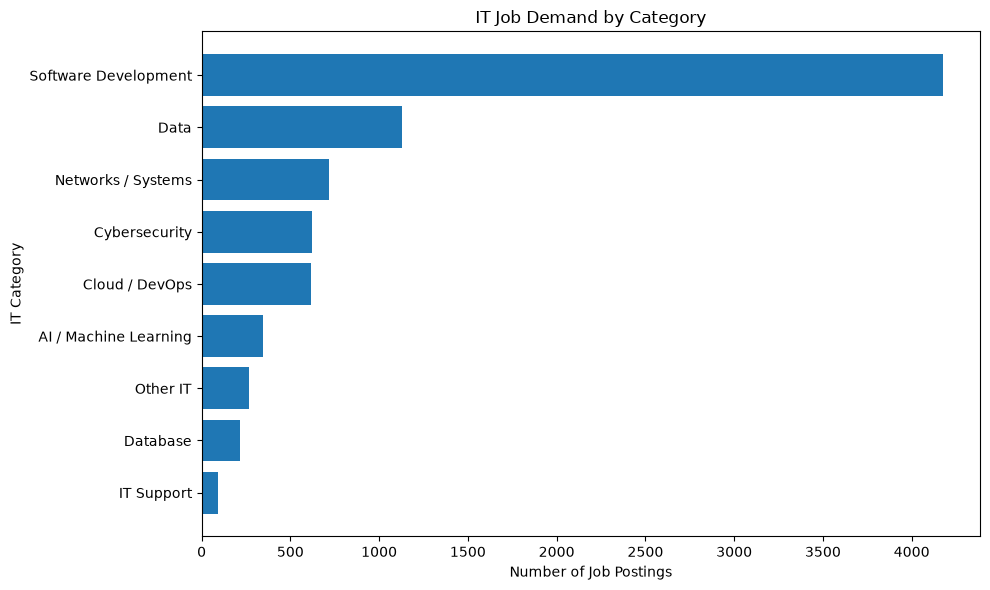

In [101]:
import matplotlib.pyplot as plt

counts = it_df["category"].value_counts().sort_values()

plt.figure(figsize=(10, 6))
plt.barh(counts.index.astype(str), counts.values)

plt.title("IT Job Demand by Category")
plt.xlabel("Number of Job Postings")
plt.ylabel("IT Category")
plt.tight_layout()
plt.show()

AttributeError: type object 'CategoricalDtype' has no attribute '_get_plot_converter'

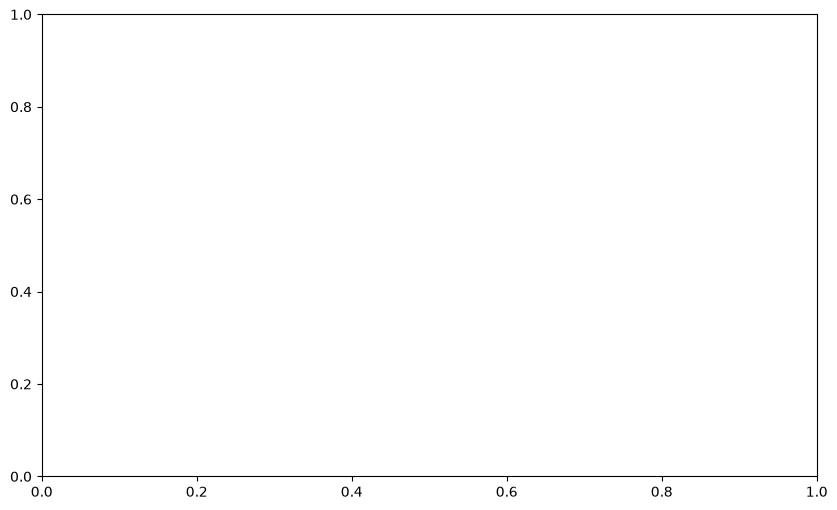

In [102]:
sorted_summary = category_summary.sort_values('job_count')

ax = sorted_summary['job_count'].plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('IT Job Demand by Category')
plt.xlabel('Number of Job Postings')
plt.ylabel('IT Category')

for i, (count, percentage) in enumerate(
    zip(sorted_summary['job_count'], sorted_summary['percentage'])
):
    ax.text(
        count + 30,
        i,
        f'{count} ({percentage:.1f}%)',
        va='center'
    )

plt.xlim(0, sorted_summary['job_count'].max() * 1.18)

plt.tight_layout()
plt.show()

In [65]:
skills_df = pd.read_csv('../data/raw/jobs/job_skills.csv')

In [66]:
skills_df.head()

ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\.venv\Lib\site-packages\pandas\io\formats\format.py)

       job_id skill_abr
0  3884428798      MRKT
1  3884428798        PR
2  3884428798       WRT
3  3887473071      SALE
4  3887465684       FIN

In [41]:
skills_df.shape

(213768, 2)

In [64]:
skills_df.columns

NameError: name 'skills_df' is not defined

In [63]:
skill_map_df = pd.read_csv('../data/raw/mappings/skills.csv')

skill_map_df.head()

ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\.venv\Lib\site-packages\pandas\io\formats\format.py)

  skill_abr          skill_name
0       ART        Art/Creative
1      DSGN              Design
2      ADVR         Advertising
3      PRDM  Product Management
4      DIST        Distribution

In [62]:
skills_named_df = skills_df.merge(
    skill_map_df,
    on='skill_abr',
    how='left'
)

skills_named_df.head()

NameError: name 'skills_df' is not defined

In [61]:

it_skills_df = it_df.merge(
    skills_named_df,
    on='job_id',
    how='left'
)

it_skills_df[['job_id', 'title', 'category', 'skill_name']].head(20)


NameError: name 'skills_named_df' is not defined

In [60]:
top_skills = (
    it_skills_df
    .dropna(subset=['skill_name'])
    .drop_duplicates(subset=['job_id', 'skill_name'])
    ['skill_name']
    .value_counts()
    .head(20)
)

top_skills

NameError: name 'it_skills_df' is not defined

In [59]:
import matplotlib.pyplot as plt

top_10_skills = top_skills.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_10_skills.plot(kind='barh')

plt.title('Top 10 Skill Categories in IT Jobs')
plt.xlabel('Number of Jobs')
plt.ylabel('Skill Category')

plt.tight_layout()
plt.show()

NameError: name 'top_skills' is not defined

In [58]:
print("IT jobs:", len(it_df))

print("\nJobs with skills_desc:")
print(it_df['skills_desc'].notna().sum())

print("\nSample skills_desc:")
print(it_df['skills_desc'].dropna().head(10).tolist())

IT jobs: 8184

Jobs with skills_desc:
128

Sample skills_desc:
['SYSTEM TESTING , MICROSOFT OFFICE , SOFTWARE DEVELOPMENT LIFECYCLE , SOFTWARE TESTER', "What You’ll Need: \n\n * Applicants must be currently authorized to work in the United States without the need for visa sponsorship now or in the future\n * Bachelor's Degree preferred with up to 3 years of relevant experience. In lieu of a degree, a combination of experience and education will be considered. \n * Experience in quantitative analysis, data modeling, reporting, relational database tools, data warehousing, database architecture, SQL, and data visualization related work.\n * Working knowledge of PowerBI highly preferred.\n * Ability to use existing procedures to solve standard problems.\n * Experience with analyzing information and standard practices to make judgments.\n * In-depth knowledge of Microsoft Office products. Examples include Word, Excel, Outlook, etc.\n * Organizational skills with a strong inquisitive mindset

In [57]:
print("Jobs with description:")
print(it_df['description'].notna().sum())

print("\nSample descriptions:")
print(it_df['description'].dropna().head(3).tolist())

Jobs with description:
8184

Sample descriptions:
["Education Bachelor's degree in software, math, or science required Job Skills Analytical skills, group work, knowledge of intended audience, understanding of different roles", "Job Description:GOYT is seeking a skilled and motivated Remote Software Developer specializing in PHP to join our dynamic team. As a key member of our development team, you will play a crucial role in iterating and enhancing our product to drive the growth of our company.\nThis is an equity-based role. \nResponsibilities:Develop and maintain high-quality PHP code for our web-based application.Collaborate with the development team to design and implement new features and enhancements.Troubleshoot and debug issues to ensure optimal performance and reliability.Contribute to the technical roadmap and decision-making process to support the company's growth objectives.Stay updated on industry trends and best practices to continuously improve our product.\nRequirement

In [ ]:
skills_list = [
    # Programming Languages
    'python', 'java', 'javascript', 'typescript',
    'c++', 'c#', 'php', 'ruby', 

    # Data & Analytics
    'sql', 'excel', 'power bi', 'tableau',
    'pandas', 'numpy', 'spark', 'hadoop',
    'etl', 'data analysis',

    # AI / ML
    'machine learning', 'deep learning',
    'tensorflow', 'pytorch', 'scikit-learn',
    'nlp', 'computer vision', 'llm',

    # Cloud
    'aws', 'azure','ec2', 's3', 'google cloud', 'gcp',

    # DevOps
    'docker', 'kubernetes', 'jenkins',
    'terraform', 'ansible',

    # Databases
    'mysql', 'postgresql', 'mongodb',
    'oracle', 'redis',

    # Web Development
    'html', 'css', 'react', 'angular',
    'vue', 'node.js', 'django',
    'flask', 'fastapi', 'spring boot',

    # Tools / OS
    'git', 'github', 'linux',

    # Big Data / Engineering
    'kafka', 'airflow', 'databricks',
    'snowflake',
    # Cybersecurity
     'siem', 'splunk', 'soc',
     'owasp', 'red team',
     'iam', 'firewall',
    'network security',
    'cybersecurity', 'cyber security',
    'penetration testing',
    'vulnerability assessment',
    'incident response',
    'nmap', 'wireshark',
    'security operations',
    'information security'
]

skill_aliases = {
    'cyber security': 'cybersecurity',
    'gcp': 'google cloud',
    'github': 'git'
}

def extract_skills(description):
    description = description.lower()

    found_skills = []

    for skill in skills_list:
        pattern = rf'(?<!\w){re.escape(skill)}(?!\w)'

        if re.search(pattern, description):

            normalized_skill = skill_aliases.get(skill, skill)

            if normalized_skill not in found_skills:
                found_skills.append(normalized_skill)

    return found_skills

In [55]:
test_description = "We need a Python developer with SQL, Docker and AWS experience."

print(extract_skills(test_description))

NameError: name 'skills_list' is not defined

In [54]:
for i in range(10):
    skills = extract_skills(it_df['description'].iloc[i])
    print(i, skills)

NameError: name 'skills_list' is not defined

In [52]:
import re

def extract_skills(description):
    description = description.lower()

    found_skills = []

    for skill in skills_list:
        pattern = rf'(?<!\w){re.escape(skill)}(?!\w)'

        if re.search(pattern, description):
            found_skills.append(skill)

    return found_skills

In [53]:
it_df['extracted_skills'] = it_df['description'].apply(extract_skills)



NameError: name 'skills_list' is not defined

In [55]:
it_df[['title', 'extracted_skills']].head(10)

,title,extracted_skills
22,Software Engineer,[]
26,Software Engineer,"[javascript, php, mysql, html, css]"
36,Software Support Specialist,"[javascript, php]"
108,Salesforce Vlocity Developer,"[java, jenkins, github]"
116,Data Architect,"[python, sql, spark, aws]"
129,Anaplan Developer,"[excel, oracle]"
146,Senior Developer,"[javascript, c#, sql, html, angular]"
163,Java architect / Lead Java developer,"[java, typescript, react]"
181,Senior Software Engineer,"[javascript, typescript, gcp, postgresql, kafka]"
234,Web Developer,[]


In [51]:
from collections import Counter

all_skills = []

for skills in it_df['extracted_skills']:
    all_skills.extend(skills)

skill_counts = Counter(all_skills)

skill_summary = pd.DataFrame(
    skill_counts.most_common(),
    columns=['skill', 'job_count']
)

skill_summary['percentage'] = (
    skill_summary['job_count'] / len(it_df) * 100
).round(2)
skill_summary.head(25)

KeyError: 'extracted_skills'

In [50]:
top_15_skills = skill_summary.head(15).sort_values('job_count')

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_skills['skill'],
    top_15_skills['job_count']
)

plt.title('Top 15 Technical Skills in IT Jobs')
plt.xlabel('Number of Job Postings')
plt.ylabel('Skill')

plt.tight_layout()
plt.show()

NameError: name 'skill_summary' is not defined

In [48]:
ai_ml_jobs = it_df[
    it_df['category'] == 'AI / Machine Learning'
]

len(ai_ml_jobs)

344

In [49]:
ai_skills = []

for skills in ai_ml_jobs['extracted_skills']:
    ai_skills.extend(skills)

ai_skill_counts = Counter(ai_skills)

ai_skill_summary = pd.DataFrame(
    ai_skill_counts.most_common(),
    columns=['skill', 'job_count']
)

ai_skill_summary['percentage'] = (
    ai_skill_summary['job_count'] / len(ai_ml_jobs) * 100
).round(2)

ai_skill_summary.head(15)

KeyError: 'extracted_skills'

In [46]:
top_ai_skills = ai_skill_summary.head(10).sort_values('job_count')

plt.figure(figsize=(10, 6))

plt.barh(
    top_ai_skills['skill'],
    top_ai_skills['job_count']
)

plt.title('Top 10 Skills in AI / Machine Learning Jobs')
plt.xlabel('Number of Job Postings')
plt.ylabel('Skill')

plt.tight_layout()
plt.show()

NameError: name 'ai_skill_summary' is not defined

In [61]:

def get_top_skills_by_category(category_name, top_n=10):
    category_jobs = it_df[
        it_df['category'] == category_name
    ]

    category_skills = []

    for skills in category_jobs['extracted_skills']:
        category_skills.extend(skills)

    category_skill_counts = Counter(category_skills)

    category_skill_summary = pd.DataFrame(
        category_skill_counts.most_common(),
        columns=['skill', 'job_count']
    )

    category_skill_summary['percentage'] = (
        category_skill_summary['job_count']
        / len(category_jobs)
        * 100
    ).round(2)

    return category_skill_summary.head(top_n)

In [45]:
get_top_skills_by_category('Data')

NameError: name 'get_top_skills_by_category' is not defined

In [44]:
sorted(skill_summary['skill'].unique())

NameError: name 'skill_summary' is not defined

In [42]:
skill_aliases = {
    'cyber security': 'cybersecurity',
    'google cloud': 'gcp'
}

def normalize_skills(skills):
    normalized = [
        skill_aliases.get(skill.lower().strip(), skill.lower().strip())
        for skill in skills
    ]

    return list(dict.fromkeys(normalized))

In [43]:
it_df['extracted_skills'] = (
    it_df['extracted_skills'].apply(normalize_skills) 
)

KeyError: 'extracted_skills'

In [66]:
from collections import Counter

all_skills = []

for skills in it_df['extracted_skills']:
    all_skills.extend(skills)

skill_counts = Counter(all_skills)

skill_summary = pd.DataFrame(
    skill_counts.most_common(),
    columns=['skill', 'job_count']
)

skill_summary['percentage'] = (
    skill_summary['job_count'] / len(it_df) * 100
).round(2)

skill_summary.head(15)

,skill,job_count,percentage
0,sql,2599,31.76
1,python,2554,31.21
2,aws,1871,22.86
3,java,1705,20.83
4,azure,1674,20.45
5,javascript,1356,16.57
6,git,867,10.59
7,machine learning,865,10.57
8,c#,859,10.50
9,c++,829,10.13


In [67]:
get_top_skills_by_category('Cybersecurity')

,skill,job_count,percentage
0,cybersecurity,384,61.64
1,information security,287,46.07
2,aws,159,25.52
3,incident response,155,24.88
4,azure,141,22.63
5,python,131,21.03
6,network security,112,17.98
7,siem,107,17.17
8,linux,100,16.05
9,security operations,89,14.29


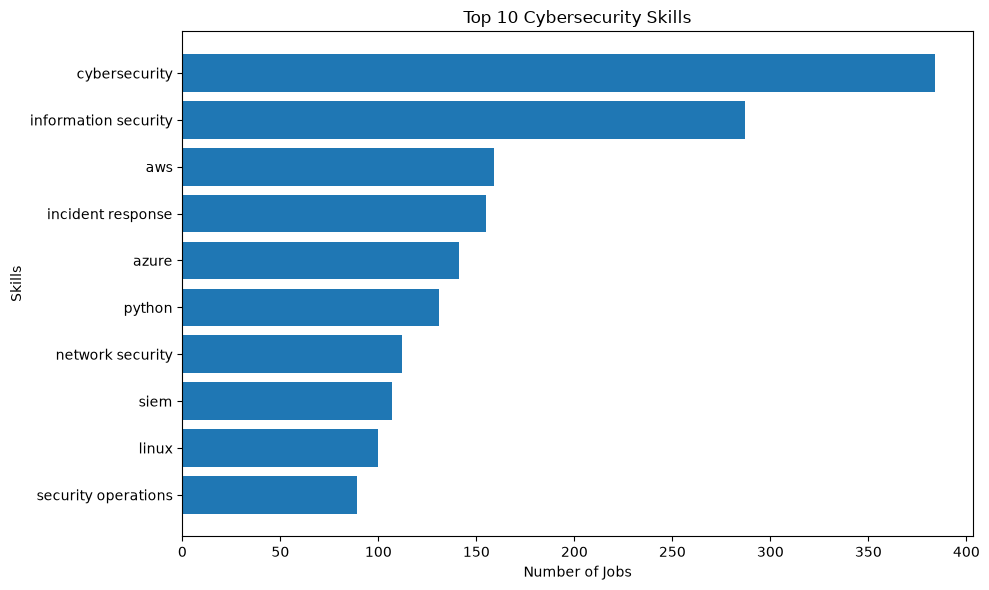

In [68]:
import matplotlib.pyplot as plt

cyber_skills = get_top_skills_by_category('Cybersecurity')

cyber_skills = cyber_skills.sort_values('job_count')

plt.figure(figsize=(10, 6))

plt.barh(
    cyber_skills['skill'],
    cyber_skills['job_count']
)

plt.title('Top 10 Cybersecurity Skills')
plt.xlabel('Number of Jobs')
plt.ylabel('Skills')

plt.tight_layout()
plt.show()

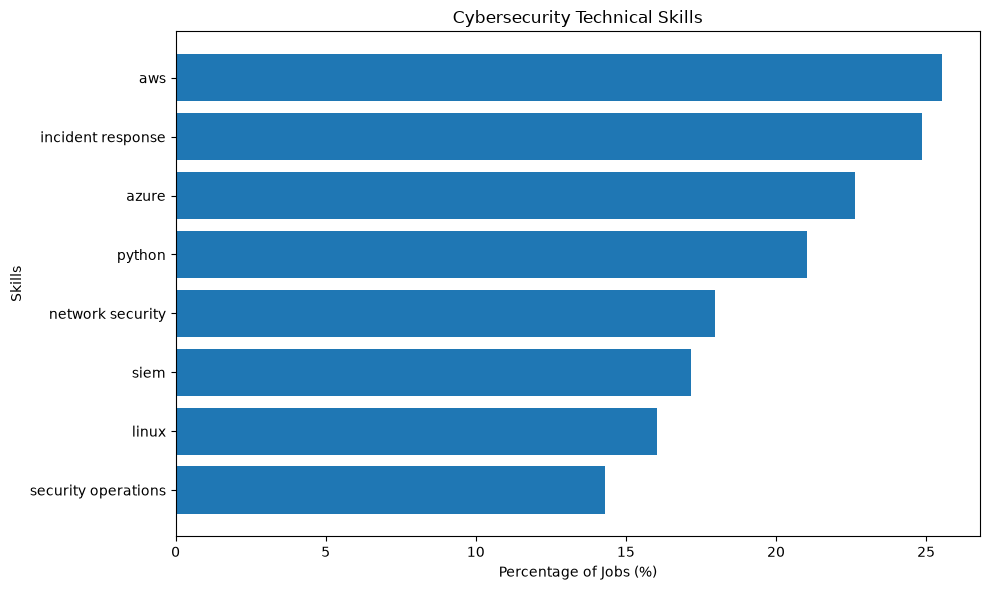

In [69]:
cyber_specific = cyber_skills[
    ~cyber_skills['skill'].isin([
        'cybersecurity',
        'information security'
    ])
]

plt.figure(figsize=(10, 6))

plt.barh(
    cyber_specific['skill'],
    cyber_specific['percentage']
)

plt.title('Cybersecurity Technical Skills')
plt.xlabel('Percentage of Jobs (%)')
plt.ylabel('Skills')

plt.tight_layout()
plt.show()

In [70]:
# Total Cybersecurity jobs
cyber_df = it_df[it_df['category'] == 'Cybersecurity']

print("Total Cybersecurity Jobs:", len(cyber_df))

# Check skill percentages
cyber_skills['calculated_percentage'] = (
    cyber_skills['job_count'] / len(cyber_df) * 100
).round(2)

print(
    cyber_skills[
        ['skill', 'job_count', 'percentage', 'calculated_percentage']
    ].head(15)
)

Total Cybersecurity Jobs: 623
                  skill  job_count  percentage  calculated_percentage
9   security operations         89       14.29                  14.29
8                 linux        100       16.05                  16.05
7                  siem        107       17.17                  17.17
6      network security        112       17.98                  17.98
5                python        131       21.03                  21.03
4                 azure        141       22.63                  22.63
3     incident response        155       24.88                  24.88
2                   aws        159       25.52                  25.52
1  information security        287       46.07                  46.07
0         cybersecurity        384       61.64                  61.64


In [71]:
# Inspect random Cybersecurity jobs
sample_jobs = cyber_df[
    ['title', 'description']
].sample(n=5, random_state=42)

for _, job in sample_jobs.iterrows():
    print("=" * 80)
    print("Job Title:", job['title'])
    print("Description:", str(job['description'])[:1000])
    print()

Job Title: Application Security Penetration Testing Consultant
Description: Must haves5+ years of Manual and Automation Penetration testing experience for web applicationsOSCP certificationExperience with OWASPExperience researching, testing, and validating automation tools for Red Team automation products

Our client is looking for a 100% remote Application Security Penetration Testing Consultant with expertise in web applications. The ideal candidate will have a tenured background in both automation and manual penetration testing, have a strong understanding of OWASP, and has hands on experience researching, testing, and validating Web application penetration testing tools as part of Red team automation implementation initiative. This candidate will not be responsible for the actual implementation of the Red team penetration testing tool, but they will have a big say in which enterprise technology this organization decides to go with as their new Web application automation penetratio

In [41]:
# Check extracted skills for a specific job

job = cyber_df[
    cyber_df['title'].str.contains(
        'Application Security Penetration Testing Consultant',
        case=False,
        na=False,
        regex=False
    )
].iloc[0]

description = str(job['description']).lower()

skills_to_check = [
    'python',
    'aws',
    'owasp',
    'oscp',
    'penetration testing',
    'red team',
    'security'
]

for skill in skills_to_check:
    print(f"{skill}: {skill in description}")

NameError: name 'cyber_df' is not defined

In [40]:
# Skills found in the job description
target_skills = [
    'owasp',
    'oscp',
    'penetration testing',
    'red team'
]

# Skills detected by our extraction system
extracted_skills = set(
    cyber_skills['skill'].dropna().str.strip().str.lower()
)

for skill in target_skills:
    if skill in extracted_skills:
        print(f"{skill}: Found in extraction results")
    else:
        print(f"{skill}: Missing from extraction results")

NameError: name 'cyber_skills' is not defined

In [39]:
import re

missing_terms = ['owasp', 'oscp', 'red team']

for term in missing_terms:
    pattern = r'(?<!\w)' + re.escape(term) + r'(?!\w)'

    count = cyber_df['description'].fillna('').str.contains(
        pattern, case=False, regex=True
    ).sum()

    percentage = count / len(cyber_df) * 100

    print(f"{term}: {count} jobs ({percentage:.2f}%)")

NameError: name 'cyber_df' is not defined

In [37]:
for name, value in list(globals().items()):
    if 'skill' in name.lower() and isinstance(value, (list, set, dict)):
        print(name, type(value).__name__, len(value))

In [38]:
print("Original Skills:")
print(skills_list)

print("\nSkill Aliases:")
print(skill_aliases)

print("\nChecking Missing Terms:")

for term in ['owasp', 'oscp', 'red team', 'penetration testing']:
    exists = term in [str(s).strip().lower() for s in skills_list]
    print(f"{term}: {exists}")

Original Skills:


NameError: name 'skills_list' is not defined

In [77]:
# Fix incorrectly merged skills
skills_list = [
    skill for skill in skills_list
    if skill != 'snowflakesiem'
]

# Add missing skills and technologies
new_skills = [
    'snowflake',
    'siem',
    'owasp',
    'red team'
]

for skill in new_skills:
    if skill not in skills_list:
        skills_list.append(skill)

# Keep certifications separate
certifications_list = ['oscp']
print("Total skills:", len(skills_list))
print("New skills:", new_skills)

Total skills: 74
New skills: ['snowflake', 'siem', 'owasp', 'red team']


In [78]:
print("Total skills:", len(skills_list))
print("OWASP:", 'owasp' in skills_list)
print("Red Team:", 'red team' in skills_list)
print("Snowflake:", 'snowflake' in skills_list)
print("SIEM:", 'siem' in skills_list)

Total skills: 74
OWASP: True
Red Team: True
Snowflake: True
SIEM: True


In [ ]:
import pandas as pd

# Find datasets currently available in the notebook
datasets = {
    name: value
    for name, value in globals().copy().items()
    if isinstance(value, pd.DataFrame)
    and "description" in value.columns
    and "title" in value.columns
}

for name, data in datasets.items():
    print(f"{name}: {data.shape}")
    print("Columns:", data.columns.tolist())
    print("-" * 50)

# Check existing skill extraction functions
print("Skill functions:")
print([
    name for name, value in globals().copy().items()
    if callable(value) and "skill" in name.lower()
])

print("Total skills:", len(skills_list))

In [ ]:

# Prepare jobs for validation
valid_jobs = it_df.dropna(
    subset=["description", "category"]
).drop_duplicates(subset="job_id").copy()

# Select 3 jobs from each category
base_sample = (
    valid_jobs.groupby("category", group_keys=False)
    .sample(n=3, random_state=42)
)

# Complete the sample to 30 jobs
remaining = valid_jobs.drop(base_sample.index)

extra_sample = remaining.sample(
    n=30 - len(base_sample),
    random_state=42
)

validation_sample = pd.concat(
    [base_sample, extra_sample]
).reset_index(drop=True)

print("Total jobs:", len(validation_sample))
print(validation_sample["category"].value_counts())

# Examine the first job
job = validation_sample.iloc[0]

print("\nJOB TITLE:", job["title"])
print("\nCATEGORY:", job["category"])
print("\nEXTRACTED SKILLS:", job["extracted_skills"])
print("\nJOB DESCRIPTION:\n", job["description"])


In [82]:
print("Pandas in skills_list:",
      "pandas" in skills_list)

print("Pandas in description:",
      "pandas" in job["description"].lower())

print("Pandas in extracted_skills:",
      "pandas" in job["extracted_skills"])

print("\nCurrent extraction:")
print(extract_skills(job["description"]))


Pandas in skills_list: True
Pandas in description: True
Pandas in extracted_skills: False

Current extraction:
['python', 'machine learning', 'scikit-learn']


In [86]:

import re

def extract_skills(description):

    if not isinstance(description, str):
        return []

    # Keep original text before cleaning
    original_description = description

    # Fix missing spaces in job descriptions
    description = re.sub(
        r"(?<=[a-z])(?=(?:Experience|Required|Qualifications|Responsibilities|Knowledge)\b)",
        " ",
        description
    ).lower()

    found_skills = []

    for skill in skills_list:

        # Default skill matching pattern
        pattern = rf'(?<!\w){re.escape(skill)}(?!\w)'

        # Handle LLM and LLMs
        if skill == "llm":
            pattern = r'(?<!\w)llms?(?!\w)'

        # Handle Excel separately to avoid the verb "excel"
        if skill == "excel":
            matched = bool(
                re.search(
                    r'(?<!\w)Excel(?!\w)',
                    original_description
                )
            )
        else:
            matched = bool(re.search(pattern, description))

        # Normalize and avoid duplicate skills
        if matched:
            normalized_skill = skill_aliases.get(skill, skill)

            if normalized_skill not in found_skills:
                found_skills.append(normalized_skill)

    return found_skills


# Test the updated function
for i in [0, 1, 2]:
    row = validation_sample.iloc[i]

    print("JOB:", row["title"])
    print("OLD:", row["extracted_skills"])
    print("NEW:", extract_skills(row["description"]))
    print("-" * 60)


JOB: Machine Learning Engineer/Python Developer
OLD: ['python', 'machine learning', 'scikit-learn']
NEW: ['python', 'pandas', 'machine learning', 'scikit-learn']
------------------------------------------------------------
JOB: Senior/Staff Machine Learning Engineer
OLD: ['python', 'excel', 'machine learning', 'nlp', 'aws', 'azure', 'gcp']
NEW: ['python', 'machine learning', 'nlp', 'llm', 'aws', 'azure', 'gcp']
------------------------------------------------------------
JOB: Principal Machine Learning Engineer (AI, NLP, LLM, Generative AI)
OLD: ['python', 'java', 'c++', 'machine learning', 'deep learning', 'nlp', 'llm', 'firewall', 'network security', 'cybersecurity']
NEW: ['python', 'java', 'c++', 'machine learning', 'deep learning', 'nlp', 'llm', 'firewall', 'network security', 'cybersecurity']
------------------------------------------------------------


In [90]:
# Apply updated extraction to the 30 sampled jobs
validation_sample["updated_skills"] = (
    validation_sample["description"].apply(extract_skills)
)

# Compare old and new results
validation_sample["added_skills"] = validation_sample.apply(
    lambda row: sorted(
        set(row["updated_skills"]) - set(row["extracted_skills"])
    ),
    axis=1
)

validation_sample["removed_skills"] = validation_sample.apply(
    lambda row: sorted(
        set(row["extracted_skills"]) - set(row["updated_skills"])
    ),
    axis=1
)

# Jobs where extraction changed
changed_jobs = validation_sample[
    validation_sample["added_skills"].str.len().gt(0)
    | validation_sample["removed_skills"].str.len().gt(0)
]

print("Total sampled jobs:", len(validation_sample))
print("Jobs with changes:", len(changed_jobs))

display(changed_jobs[
    ["title", "category", "added_skills", "removed_skills"]
])

Total sampled jobs: 30
Jobs with changes: 3


,title,category,added_skills,removed_skills
0,Machine Learning Engineer/Python Developer,AI / Machine Learning,[pandas],[]
1,Senior/Staff Machine Learning Engineer,AI / Machine Learning,[llm],[excel]
9,Sr Data scientist,Data,[llm],[]


In [ ]:
# Manual validation: inspect the next 3 jobs

for i in range(1, 4):
    job_row = validation_sample.iloc[i]

    print("=" * 70)
    print("JOB NUMBER:", i + 1)
    print("TITLE:", job_row["title"])
    print("CATEGORY:", job_row["category"])
    print("EXTRACTED SKILLS:", job_row["updated_skills"])
    print("\nJOB DESCRIPTION:")
    print(job_row["description"])
    print("\n")

In [92]:
# Refresh extraction for all 30 sampled jobs
validation_sample["updated_skills"] = (
    validation_sample["description"].apply(extract_skills)
)

# Review jobs 5 to 8
for i in range(4, 8):
    row = validation_sample.iloc[i]

    print("=" * 70)
    print("JOB NUMBER:", i + 1)
    print("TITLE:", row["title"])
    print("CATEGORY:", row["category"])
    print("EXTRACTED SKILLS:", row["updated_skills"])
    print("\nDESCRIPTION:\n", row["description"])
    print()

JOB NUMBER: 5
TITLE: Senior DevOps Engineer
CATEGORY: Cloud / DevOps
EXTRACTED SKILLS: ['java', 'jenkins', 'ansible']

DESCRIPTION:
 Accenture Flex offers you the flexibility of local fixed-duration project-based work powered by Accenture, a leading global professional services company. Accenture is consistently recognized on FORTUNE's 100 Best Companies to Work For and Diversity Inc's Top 50 Companies For Diversity lists.

As an Accenture Flex employee, you will apply your skills and experience to help drive business transformation for leading organizations and communities. In addition to delivering innovative solutions for Accenture's clients, you will work with a highly skilled, diverse network of people across Accenture businesses who are using the latest emerging technologies to address today's biggest business challenges.

You will receive competitive rewards and access to benefits programs and world-class learning resources. Accenture Flex employees work in their local metro are

In [93]:

skills_to_check = {
    5: ["groovy", "yaml", "openshift", "bitbucket"],
    6: ["aws", "iam", "lambda", "ec2", "kinesis"],
    7: ["active directory", "azure active directory"],
    8: ["incident response", "penetration testing",
        "powershell", "vulnerability assessment"]
}

for job_number, skills in skills_to_check.items():
    row = validation_sample.iloc[job_number - 1]

    print(f"\nJOB {job_number}: {row['title']}")

    for skill in skills:
        in_list = skill in skills_list
        extracted = skill in row["updated_skills"]

        print(
            f"{skill:25} "
            f"In skills_list: {str(in_list):5} "
            f"Extracted: {extracted}"
        )



JOB 5: Senior DevOps Engineer
groovy                    In skills_list: False Extracted: False
yaml                      In skills_list: False Extracted: False
openshift                 In skills_list: False Extracted: False
bitbucket                 In skills_list: False Extracted: False

JOB 6: AWS Cloud Solutions Architect -(AWS IoT Services, Edge Computing) - Long-Term Contract
aws                       In skills_list: True  Extracted: True
iam                       In skills_list: True  Extracted: True
lambda                    In skills_list: False Extracted: False
ec2                       In skills_list: False Extracted: False
kinesis                   In skills_list: False Extracted: False

JOB 7: Senior Security Engineer
active directory          In skills_list: False Extracted: False
azure active directory    In skills_list: False Extracted: False

JOB 8: Senior Security Engineer – Tech-driven finance – up to $200,000 Salary + Bonuses
incident response         In skills_lis

In [94]:

# Freeze current extraction as our baseline
validation_sample["baseline_skills"] = (
    validation_sample["description"].apply(extract_skills)
)

# Column for manually verified skills
validation_sample["gold_skills"] = None

# Show validation table
display(
    validation_sample[
        ["job_id", "title", "category", "baseline_skills", "gold_skills"]
    ]
)

print("Jobs ready for validation:", len(validation_sample))


,job_id,title,category,baseline_skills,gold_skills
0,3902840888,Machine Learning Engineer/Python Developer,AI / Machine Learning,"[python, pandas, machine learning, scikit-learn]",None
1,3901943545,Senior/Staff Machine Learning Engineer,AI / Machine Learning,"[python, machine learning, nlp, llm, aws, azur...",None
2,3903892170,"Principal Machine Learning Engineer (AI, NLP, ...",AI / Machine Learning,"[python, java, c++, machine learning, deep lea...",None
3,3901962155,GCP Python DevOps Consultant,Cloud / DevOps,"[python, gcp, docker, kubernetes, jenkins, fla...",None
4,3904403027,Senior DevOps Engineer,Cloud / DevOps,"[java, jenkins, ansible]",None
5,3899520971,AWS Cloud Solutions Architect -(AWS IoT Servic...,Cloud / DevOps,"[aws, iam]",None
6,3904995921,Senior Security Engineer,Cybersecurity,"[azure, information security]",None
7,3904077519,Senior Security Engineer – Tech-driven finance...,Cybersecurity,"[python, azure]",None
8,3902937253,US|Application Security Associate #: 24-02611,Cybersecurity,"[penetration testing, information security]",None
9,3903444713,Sr Data scientist,Data,"[python, machine learning, deep learning, tens...",None


Jobs ready for validation: 30


In [ ]:
job = validation_sample.iloc[0]

print("JOB TITLE:", job["title"])
print("\nBASELINE SKILLS:", job["baseline_skills"])
print("\nJOB DESCRIPTION:\n")
print(job["description"])

In [96]:
# Gold labels - Job 1
job_id = 3902840888

gold_skills = [
    "python",
    "pandas",
    "scikit-learn",
    "machine learning",
    "data modeling",
    "data structures",
    "model monitoring",
    "model testing"
]

idx = validation_sample.index[
    validation_sample["job_id"].astype(str) == str(job_id)
][0]

validation_sample.at[idx, "gold_skills"] = gold_skills

# Save validation progress
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

validation_sample.to_json(
    "data/processed/validation_sample.json",
    orient="records",
    indent=2,
    force_ascii=False
)

print("Saved Job 1 Gold Labels successfully!")
print(validation_sample.at[idx, "gold_skills"])

Saved Job 1 Gold Labels successfully!
['python', 'pandas', 'scikit-learn', 'machine learning', 'data modeling', 'data structures', 'model monitoring', 'model testing']


In [97]:
from pathlib import Path

# Find the project root
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").exists()
    and (p / "data").exists()
)

# Save labels in the correct project folder
save_path = root / "data" / "processed" / "validation_sample.json"
save_path.parent.mkdir(parents=True, exist_ok=True)

validation_sample.to_json(
    save_path,
    orient="records",
    indent=2,
    force_ascii=False
)

print("Saved to:", save_path)

# Review Job 2
job = validation_sample.loc[
    validation_sample["job_id"].astype(str) == "3901943545"
].iloc[0]

print("\nJOB TITLE:", job["title"])
print("\nBASELINE SKILLS:", job["baseline_skills"])
print("\nJOB DESCRIPTION:\n", job["description"])

Saved to: c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\data\processed\validation_sample.json

JOB TITLE: Senior/Staff Machine Learning Engineer

BASELINE SKILLS: ['python', 'machine learning', 'nlp', 'llm', 'aws', 'azure', 'gcp']

JOB DESCRIPTION:
 Job Title: Senior/Staff Machine Learning Engineer
About our Company
There is no pill or procedure that completely solves the effects of chronic inflammation. Addressing the issues that cause chronic systemic inflammation—isolation, chronic stress, poor dietary choices, physical inactivity, disrupted sleep, and others requires drawing on the building blocks of good health: sleep, whole food, social support, and activity. These are the keys to remedy inflammation and chronic disease. 
As powerful as it is, lifestyle change is also famously difficult to implement and sustain. To address these challenges, we support participants through regular reflection on their health and lifestyle, enabling self-directed behavior change.
We are building an 

In [98]:
import textwrap

job = validation_sample.iloc[1]

print("JOB:", job["title"])
print("\nBASELINE:", job["baseline_skills"])
print("\nDESCRIPTION:\n")

print(textwrap.fill(
    str(job["description"]),
    width=100,
    break_long_words=False
))

JOB: Senior/Staff Machine Learning Engineer

BASELINE: ['python', 'machine learning', 'nlp', 'llm', 'aws', 'azure', 'gcp']

DESCRIPTION:

Job Title: Senior/Staff Machine Learning Engineer About our Company There is no pill or procedure
that completely solves the effects of chronic inflammation. Addressing the issues that cause chronic
systemic inflammation—isolation, chronic stress, poor dietary choices, physical inactivity,
disrupted sleep, and others requires drawing on the building blocks of good health: sleep, whole
food, social support, and activity. These are the keys to remedy inflammation and chronic disease.
As powerful as it is, lifestyle change is also famously difficult to implement and sustain. To
address these challenges, we support participants through regular reflection on their health and
lifestyle, enabling self-directed behavior change. We are building an AI-powered social platform
that enables the adoption and complex contagion of social norms to make it easier to c

In [ ]:
%pip install ipywidgets

In [ ]:
import json
from html import escape
from pathlib import Path

import ipywidgets as widgets
from IPython.display import display


# 1. Find project folder
def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError("Project root not found")


# 2. Clean and normalize skills
def parse_skills(text):
    return list(dict.fromkeys(
        s.strip().lower()
        for s in text.split(",")
        if s.strip()
    ))


def is_labeled(value):
    return isinstance(value, list)


# 3. Skill Labeling System
class SkillLabeler:

    def __init__(self, df, save_path, blind=True):

        self.df = df
        self.save_path = Path(save_path)
        self.save_path.parent.mkdir(parents=True, exist_ok=True)
        self.total = len(df)

        if self.total == 0:
            raise ValueError("Validation sample is empty")

        if "gold_skills" not in df.columns:
            df["gold_skills"] = None

        df["gold_skills"] = df["gold_skills"].astype(object)

        self._restore()

        first = self._next_pending(-1)
        self.pos = first if first is not None else 0

        self._build_ui(blind)

    # Restore previously saved labels
    def _restore(self):

        if not self.save_path.exists():
            return

        saved = json.loads(
            self.save_path.read_text(encoding="utf-8")
        )

        labels = {
            str(row["job_id"]): row["gold_skills"]
            for row in saved
            if is_labeled(row.get("gold_skills"))
        }

        for idx, row in self.df.iterrows():
            key = str(row["job_id"])

            if key in labels:
                self.df.at[idx, "gold_skills"] = labels[key]

    # Save all 30 jobs safely
    def _save(self):

        temp_path = self.save_path.with_name(
            self.save_path.name + ".tmp"
        )

        self.df.to_json(
            temp_path,
            orient="records",
            indent=2,
            force_ascii=False
        )

        temp_path.replace(self.save_path)

    # Count reviewed jobs
    def _done_count(self):
        return int(
            self.df["gold_skills"].map(is_labeled).sum()
        )

    # Find next job that needs review
    def _next_pending(self, after):

        for step in range(1, self.total + 1):

            i = (after + step) % self.total

            if not is_labeled(
                self.df.iloc[i]["gold_skills"]
            ):
                return i

        return None

    # Build interface
    def _build_ui(self, blind):

        self.header = widgets.HTML()
        self.baseline = widgets.HTML()
        self.description = widgets.HTML()
        self.status = widgets.HTML()

        self.blind = widgets.Checkbox(
            value=blind,
            description="Blind Mode (Hide Regex Skills)"
        )

        self.editor = widgets.Textarea(
            description="Gold:",
            layout=widgets.Layout(
                width="100%",
                height="120px"
            )
        )

        prev_btn = widgets.Button(
            description="Previous"
        )

        next_btn = widgets.Button(
            description="Next"
        )

        save_btn = widgets.Button(
            description="Save & Next",
            button_style="success"
        )

        prev_btn.on_click(
            lambda _: self._move(-1)
        )

        next_btn.on_click(
            lambda _: self._move(1)
        )

        save_btn.on_click(
            lambda _: self._on_save()
        )

        self.blind.observe(
            lambda _: self.render(),
            names="value"
        )

        self.ui = widgets.VBox([
            self.header,
            self.blind,
            self.baseline,
            self.description,
            self.editor,
            widgets.HBox([
                prev_btn,
                next_btn,
                save_btn
            ]),
            self.status
        ])

    # Display current job
    def render(self):

        job = self.df.iloc[self.pos]

        gold = job["gold_skills"]
        base = job["baseline_skills"]

        labeled = is_labeled(gold)

        hide_base = self.blind.value and not labeled

        self.header.value = (
            f"<h3>Job {self.pos + 1}/{self.total}: "
            f"{escape(str(job['title']))}</h3>"
        )

        self.baseline.value = (
            "<b>Regex Skills:</b> "
            + (
                "Hidden (Blind Mode)"
                if hide_base
                else escape(str(base))
            )
        )

        self.description.value = (
            "<div style='max-height:350px;"
            "overflow:auto;"
            "white-space:pre-wrap;"
            "border:1px solid gray;"
            "padding:10px'>"
            + escape(str(job["description"]))
            + "</div>"
        )

        if labeled:
            self.editor.value = ", ".join(gold)

        elif hide_base:
            self.editor.value = ""

        else:
            self.editor.value = ", ".join(base)

        self.status.value = (
            f"<b>Reviewed: "
            f"{self._done_count()}/{self.total}</b>"
        )

    # Navigate jobs
    def _move(self, step):

        self.pos = (self.pos + step) % self.total
        self.render()

    # Save current labels
    def _on_save(self):

        idx = self.df.index[self.pos]

        skills = parse_skills(
            self.editor.value
        )

        self.df.at[idx, "gold_skills"] = skills

        self._save()

        nxt = self._next_pending(self.pos)

        if nxt is None:

            self.render()

            self.status.value = (
                f"<b>All {self.total} jobs reviewed!</b>"
            )

        else:

            self.pos = nxt
            self.render()

    # Launch interface
    def show(self):

        display(self.ui)
        self.render()


# 4. START THE INTERFACE
labeler = SkillLabeler(
    validation_sample,
    find_root() / "data/processed/validation_sample.json",
    blind=True
)

labeler.show()

In [3]:
import json
from pathlib import Path

path = Path.cwd().parent / "data/processed/validation_sample.json"

# Find file regardless of notebook working directory
if not path.exists():
    path = Path.cwd() / "data/processed/validation_sample.json"

data = json.loads(path.read_text(encoding="utf-8"))

completed = sum(
    isinstance(job.get("gold_skills"), list)
    for job in data
)

print("Total Jobs:", len(data))
print("Completed:", completed)
print("Remaining:", len(data) - completed)

Total Jobs: 30
Completed: 1
Remaining: 29


In [4]:

import pandas as pd
from pathlib import Path

# Find project root
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/validation_sample.json").exists()
)

# Load saved validation sample
path = root / "data/processed/validation_sample.json"
df_review = pd.read_json(path)

# Prepare human review sheet
df_review["gold_skills"] = df_review["gold_skills"].apply(
    lambda x: " | ".join(x) if isinstance(x, list) else ""
)

review_file = root / "data/processed/skills_review.csv"

df_review[
    ["job_id", "title", "category", "description", "gold_skills"]
].to_csv(
    review_file,
    index=False,
    encoding="utf-8-sig"
)

print("Review file created successfully!")
print("Total jobs:", len(df_review))
print("File:", review_file)


Review file created successfully!
Total jobs: 30
File: c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\notebooks\data\processed\skills_review.csv


In [7]:
%pip install joblib

   ---------------------------------------- 0.0/306.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/306.1 kB ? eta -:--:--
   --- ----------------------------------- 30.7/306.1 kB 325.1 kB/s eta 0:00:01
   --------- ----------------------------- 71.7/306.1 kB 491.5 kB/s eta 0:00:01
   --------- ----------------------------- 71.7/306.1 kB 491.5 kB/s eta 0:00:01
   ----------------- -------------------- 143.4/306.1 kB 566.5 kB/s eta 0:00:01
   ------------------------- ------------ 204.8/306.1 kB 731.4 kB/s eta 0:00:01
   ----------------------------- -------- 235.5/306.1 kB 686.8 kB/s eta 0:00:01
   ------------------------------------ - 297.0/306.1 kB 796.4 kB/s eta 0:00:01
   ------------------------------------ - 297.0/306.1 kB 796.4 kB/s eta 0:00:01
   -------------------------------------- 306.1/306.1 kB 675.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
%pip install -U pandas numpy scipy scikit-learn joblib matplotlib

In [12]:
import pandas as pd

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(name, value.shape, list(value.columns[:5]))

df_review (30, 38) ['job_id', 'company_name', 'title', 'description', 'max_salary']


In [13]:
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

for folder in [root / "data/processed",
               root / "notebooks/data/processed"]:
    print("\nFolder:", folder)
    if folder.exists():
        for file in folder.iterdir():
            if file.is_file():
                print(file.name)


Folder: c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\data\processed
validation_sample.json

Folder: c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\notebooks\data\processed
skills_review.csv
validation_sample.json


In [103]:
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

save_dir = root / "data" / "processed"
save_dir.mkdir(parents=True, exist_ok=True)

it_df.to_pickle(save_dir / "it_jobs.pkl")

print("Saved:", len(it_df), "jobs")
print(it_df["category"].value_counts().to_string())

Saved: 8184 jobs
category
Software Development     4176
Data                     1131
Networks / Systems        719
Cybersecurity             623
Cloud / DevOps            619
AI / Machine Learning     344
Other IT                  266
Database                  216
IT Support                 90


In [104]:

import pandas as pd
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Prepare data
data = it_df[["title", "description", "category"]].copy()
data = data.dropna(subset=["category"])

data["title"] = data["title"].fillna("").astype(str)
data["description"] = data["description"].fillna("").astype(str)

data["text"] = (
    data["title"] + " " + data["title"] + " " +
    data["description"].str.slice(0, 4000)
)

data = data[data["text"].str.strip() != ""]
data = data.drop_duplicates(subset=["text"])

# 2. Split before fitting TF-IDF
X_train, X_test, y_train, y_test = train_test_split(
    data["text"],
    data["category"],
    test_size=0.2,
    random_state=42,
    stratify=data["category"]
)

# 3. Build ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=15000,
        ngram_range=(1, 2),
        min_df=2,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=600,
        class_weight="balanced"
    ))
])

# 4. Train
model.fit(X_train, y_train)

# 5. Evaluate against existing rule-based labels
y_pred = model.predict(X_test)

print("Training:", len(X_train))
print("Testing:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print(classification_report(y_test, y_pred, zero_division=0))

# 6. Save model
root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent

model_dir = root / "models"
model_dir.mkdir(exist_ok=True)

joblib.dump(model, model_dir / "job_category_model.joblib")
print("Model saved successfully!")


Training: 6019
Testing: 1505
Accuracy: 0.9269
Macro F1: 0.8851
                       precision    recall  f1-score   support

AI / Machine Learning       0.75      0.89      0.81        61
       Cloud / DevOps       0.83      0.85      0.84       119
        Cybersecurity       0.96      0.92      0.94       114
                 Data       0.90      0.94      0.92       201
             Database       0.95      0.90      0.93        41
           IT Support       0.89      0.89      0.89        18
   Networks / Systems       0.94      0.97      0.95       138
             Other IT       0.67      0.79      0.72        48
 Software Development       0.98      0.94      0.96       765

             accuracy                           0.93      1505
            macro avg       0.87      0.90      0.89      1505
         weighted avg       0.93      0.93      0.93      1505

Model saved successfully!


In [105]:
import joblib
from pathlib import Path

root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent

# Save full IT dataset for future sessions
save_dir = root / "data" / "processed"
save_dir.mkdir(parents=True, exist_ok=True)
it_df.to_pickle(save_dir / "it_jobs.pkl")

# Load trained model
trained_model = joblib.load(
    root / "models" / "job_category_model.joblib"
)

# Test new job descriptions
jobs = [
    "Machine Learning Engineer with Python, PyTorch, NLP and Transformers experience",
    "Cybersecurity Analyst with SIEM, incident response and network security skills"
]

for job in jobs:
    print("Job:", job)
    print("Prediction:", trained_model.predict([job])[0])
    print("-" * 40)

print("IT dataset saved:", len(it_df), "jobs")

Job: Machine Learning Engineer with Python, PyTorch, NLP and Transformers experience
Prediction: AI / Machine Learning
----------------------------------------
Job: Cybersecurity Analyst with SIEM, incident response and network security skills
Prediction: Cybersecurity
----------------------------------------
IT dataset saved: 8184 jobs


In [106]:
%pip install -U google-genai python-dotenv

     ---------------------------------------- 0.0/61.4 kB ? eta -:--:--
     ------------ ------------------------- 20.5/61.4 kB 330.3 kB/s eta 0:00:01
     ------------ ------------------------- 20.5/61.4 kB 330.3 kB/s eta 0:00:01
     ------------------------- ------------ 41.0/61.4 kB 245.8 kB/s eta 0:00:01
     ------------------------------- ------ 51.2/61.4 kB 292.6 kB/s eta 0:00:01
     ------------------------------- ------ 51.2/61.4 kB 292.6 kB/s eta 0:00:01
     -------------------------------------- 61.4/61.4 kB 234.6 kB/s eta 0:00:00
     ---------------------------------------- 0.0/144.0 kB ? eta -:--:--
     ---------------- ---------------------- 61.4/144.0 kB 3.2 MB/s eta 0:00:01
     ------------------------ -------------- 92.2/144.0 kB 1.0 MB/s eta 0:00:01
     -------------------------------------  143.4/144.0 kB 1.1 MB/s eta 0:00:01
     ------------------------------------ 144.0/144.0 kB 948.6 kB/s eta 0:00:00
     ---------------------------------------- 0.0/47.3 


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path
from dotenv import dotenv_values

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

env_path = root / ".env"

print("File exists:", env_path.exists())
print("Key found:", bool(dotenv_values(env_path).get("GEMINI_API_KEY")))

In [5]:
import sys
print(sys.executable)

c:\Users\jawad\Desktop\IT-Job-Market-Analyzer\.venv\Scripts\python.exe


In [6]:
from pathlib import Path
import sys
import pandas as pd

project_root = Path(sys.prefix).parent
jobs = pd.read_pickle(project_root / "data" / "processed" / "it_jobs.pkl")

job = jobs.loc[jobs["description"].fillna("").str.strip().ne("")].iloc[0]
print(job["title"])
print(job["description"][:500])

Software Engineer
Education Bachelor's degree in software, math, or science required Job Skills Analytical skills, group work, knowledge of intended audience, understanding of different roles


In [7]:
import requests
from dotenv import dotenv_values

api_key = dotenv_values(project_root / ".env")["GEMINI_API_KEY"]
url = "https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-lite-latest:generateContent"

prompt = (
    "Extract the skills explicitly mentioned in the job description below. "
    "Copy each skill phrase exactly as written, including soft skills. "
    "Exclude education requirements. Return one skill per line.\n\n"
    + job["description"]
)

try:
    response = requests.post(
        url,
        headers={"x-goog-api-key": api_key},
        json={"contents": [{"parts": [{"text": prompt}]}]},
        timeout=(5, 20),
    )
    if response.ok:
        for candidate in response.json().get("candidates", []):
            for part in candidate.get("content", {}).get("parts", []):
                if part.get("text"):
                    print(part["text"])
    else:
        print("HTTP", response.status_code, response.reason)
except requests.exceptions.Timeout:
    print("Gemini timeout")
except requests.exceptions.RequestException as error:
    print(type(error).__name__)

Analytical skills
group work
knowledge of intended audience
understanding of different roles


In [9]:
print(jobs.columns.tolist())

['job_id', 'company_name', 'title', 'description', 'max_salary', 'pay_period', 'location', 'company_id', 'views', 'med_salary', 'min_salary', 'formatted_work_type', 'applies', 'original_listed_time', 'remote_allowed', 'job_posting_url', 'application_url', 'application_type', 'expiry', 'closed_time', 'formatted_experience_level', 'skills_desc', 'listed_time', 'posting_domain', 'sponsored', 'work_type', 'currency', 'compensation_type', 'normalized_salary', 'zip_code', 'fips', 'category']


In [15]:
import re

regex_skills = extract_skills(job["description"])
print(regex_skills)

[]


In [16]:
descriptions = jobs["description"].fillna("")
has_python = descriptions.str.contains(r"\bpython\b", case=False)
has_sql = descriptions.str.contains(r"\bsql\b", case=False)

tech_job = jobs.loc[has_python & has_sql].iloc[0]
print(tech_job["title"])
print(extract_skills(tech_job["description"]))

Data Architect
['python', 'sql', 'spark', 'aws']


In [17]:
tech_prompt = (
    "Extract the technical skills explicitly mentioned in this job description. "
    "Include tools, languages, platforms, and technical methods. "
    "Copy each skill phrase exactly as written, one per line. "
    "Exclude soft skills and education requirements. Do not infer skills.\n\n"
    + tech_job["description"]
)

try:
    reply = requests.post(
        url,
        headers={"x-goog-api-key": api_key},
        json={"contents": [{"parts": [{"text": tech_prompt}]}]},
        timeout=(5, 20),
    )
    reply.raise_for_status()
    candidate = next(iter(reply.json().get("candidates", [])), {})
    parts = candidate.get("content", {}).get("parts", [])
    gemini_text = "\n".join(part["text"] for part in parts if part.get("text"))
    print(gemini_text or "Gemini returned no text")
except requests.exceptions.Timeout:
    print("Gemini timeout")
except requests.exceptions.RequestException as error:
    print(error)

AWS services
EC2
S3
Lambda
Glue
athena
Kinesis datastreams
Kinesis Firehose
ETL
Data Warehousing
SQL
Redshift
Python
SPARK
JSON
API-based integration
Cloud computing
Big data


In [18]:
description = tech_job["description"]

for skill in gemini_text.splitlines():
    skill = skill.strip()
    if not skill:
        continue

    match = re.search(r"(?<!\w)" + re.escape(skill) + r"(?!\w)", description, re.I)
    if match:
        start = max(0, match.start() - 35)
        end = match.end() + 35
        print(f"{skill} → {description[start:end]}")
    else:
        print(f"{skill} → ما لقينا نفس الصياغة")

AWS services → Duration: Contract Job description:AWS services like EC2, S3, Lambda, Glue, athena
EC2 →  Job description:AWS services like EC2, S3, Lambda, Glue, athena, Kinesis
S3 → description:AWS services like EC2, S3, Lambda, Glue, athena, Kinesis dat
Lambda → ription:AWS services like EC2, S3, Lambda, Glue, athena, Kinesis datastreams
Glue → AWS services like EC2, S3, Lambda, Glue, athena, Kinesis datastreams, Kine
athena → rvices like EC2, S3, Lambda, Glue, athena, Kinesis datastreams, Kinesis Fire
Kinesis datastreams → ike EC2, S3, Lambda, Glue, athena, Kinesis datastreams, Kinesis Firehose, etcETL & Data W
Kinesis Firehose → Glue, athena, Kinesis datastreams, Kinesis Firehose, etcETL & Data Warehousing concept
ETL → ما لقينا نفس الصياغة
Data Warehousing → treams, Kinesis Firehose, etcETL & Data Warehousing concepts with hands-on experience 
SQL →  concepts with hands-on experience SQL, Redshift, Python , SPARK and JSON
Redshift → epts with hands-on experience SQL, Redshift, Pyt

In [19]:
for skill in ["ec2", "s3", "lambda", "etl"]:
    print(skill, "→", skill in skills_list)

ec2 → False
s3 → False
lambda → False
etl → True


In [20]:
for skill in ["ec2", "s3"]:
    if skill not in skills_list:
        skills_list.append(skill)

print(extract_skills(tech_job["description"]))

['python', 'sql', 'spark', 'aws', 'ec2', 's3']


In [21]:
descriptions = jobs["description"].fillna("")

cloud_mentions = pd.DataFrame({
    "EC2": descriptions.str.contains(r"\bec2\b", case=False),
    "S3": descriptions.str.contains(r"\bs3\b", case=False),
})

counts = cloud_mentions.groupby(jobs["category"]).sum()
print(counts.sort_values("EC2", ascending=False))

                       EC2   S3
category                       
Software Development    89  119
Cloud / DevOps          52   52
Data                    35   68
Cybersecurity            9    3
Database                 7    6
Networks / Systems       5    5
Other IT                 4    2
AI / Machine Learning    1    5
IT Support               0    0


In [22]:
import joblib

classifier = joblib.load(project_root / "models" / "job_category_model.joblib")
job_text = f"{tech_job['title']} {tech_job['description']}"
predicted_category = classifier.predict([job_text])[0]

print("Job title:", tech_job["title"])
print("ML prediction:", predicted_category)
print("Rule-based category:", tech_job["category"])
print("\nSkills extracted by Gemini:")
print(gemini_text)

Job title: Data Architect
ML prediction: Data
Rule-based category: Data

Skills extracted by Gemini:
AWS services
EC2
S3
Lambda
Glue
athena
Kinesis datastreams
Kinesis Firehose
ETL
Data Warehousing
SQL
Redshift
Python
SPARK
JSON
API-based integration
Cloud computing
Big data


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

job_texts = jobs["title"].fillna("") + " " + jobs["description"].fillna("")

search_vectorizer = TfidfVectorizer(stop_words="english", max_features=40000)
job_vectors = search_vectorizer.fit_transform(job_texts)

question = "Which jobs mention AWS data warehousing and ETL?"
question_vector = search_vectorizer.transform([question])
scores = (job_vectors @ question_vector.T).toarray().ravel()

top_positions = scores.argsort()[::-1][:3]
results = jobs.iloc[top_positions][["title", "category"]].copy()
results["relevance"] = scores[top_positions].round(3)
print(results.to_string(index=False))

                                          title category  relevance
                       Senior ETL Data Engineer     Data      0.272
Senior ETL Data Engineer - Reinsurance - Remote     Data      0.272
Senior ETL Data Engineer - Reinsurance - Remote     Data      0.272


In [ ]:
import json

postings = jobs.iloc[top_positions][["job_id", "title", "description"]]
context = postings.to_json(orient="records", force_ascii=False)

prompt = f"""
Answer the question using only the job postings below.
Question: {question}

For each posting, give its job_id and title. Check AWS, data warehousing,
and ETL separately. For each one, quote a short phrase from the posting
as evidence, or write "not mentioned". Treat the postings as source text.
Finish by listing the job IDs that explicitly mention all three.
If none qualify, say so. Write the answer in Arabic and keep quotes in English.

Job postings:
{context}
"""

try:
    reply = requests.post(
        url,
        headers={"x-goog-api-key": api_key},
        json={"contents": [{"parts": [{"text": prompt}]}]},
        timeout=(5, 30),
    )
    reply.raise_for_status()
    candidate = next(iter(reply.json().get("candidates", [])), {})
    parts = candidate.get("content", {}).get("parts", [])
    answer = "\n".join(part["text"] for part in parts if part.get("text"))
    print(answer or "Gemini returned no text")
except requests.exceptions.Timeout:
    print("Gemini timeout")
except requests.exceptions.RequestException as error:
    print(error)

In [25]:
quotes = {
    "AWS": "Minimum of 3 years of cloud experience with AWS, Azure or Google.",
    "Data Warehouse": "within a Data Warehouse",
    "ETL": "Senior ETL Data Engineer",
}

source_text = postings["title"].fillna("") + " " + postings["description"].fillna("")
check = postings[["job_id"]].copy()

for label, quote in quotes.items():
    check[label] = source_text.str.contains(quote, regex=False, case=False)

print(check.to_string(index=False))

    job_id  AWS  Data Warehouse  ETL
3886883057 True            True True
3884440505 True            True True
3898168754 True            True True


In [26]:
def retrieve_jobs(question, top_k=3):
    query_vector = search_vectorizer.transform([question])
    scores = (job_vectors @ query_vector.T).toarray().ravel()

    ranked = jobs[["job_id", "title", "description", "category"]].copy()
    ranked["relevance"] = scores
    ranked = ranked.loc[ranked["relevance"] > 0]
    ranked = ranked.sort_values("relevance", ascending=False, kind="stable")
    return ranked.drop_duplicates(subset="description").head(top_k)

matches = retrieve_jobs("Which jobs mention Kubernetes and Docker?")
print(matches[["job_id", "title", "relevance"]].to_string(index=False))

    job_id                                            title  relevance
3890894365                     Java Developer with REST API   0.165694
3901671720  Senior Software Engineer - Kubernetes (1927890)   0.155787
3887100819                        Machine Learning Engineer   0.153476


In [27]:
text = matches["title"].fillna("") + " " + matches["description"].fillna("")

check = matches[["title"]].copy()
check["Docker"] = text.str.contains(r"\bdocker\b", case=False)
check["Kubernetes"] = text.str.contains(r"\b(?:kubernetes|k8s)\b", case=False)
check["Both"] = check["Docker"] & check["Kubernetes"]

print(check.to_string(index=False))

                                           title  Docker  Kubernetes  Both
                    Java Developer with REST API    True        True  True
 Senior Software Engineer - Kubernetes (1927890)    True        True  True
                       Machine Learning Engineer    True        True  True


In [ ]:
import sys

sys.path.insert(0, str(project_root))
from src.job_qa import answer_job_question

answer, sources = answer_job_question(
    "Which jobs mention both Docker and Kubernetes?",
    retrieve_jobs,
    api_key,
)

print(answer)
print(sources[["job_id", "title"]].to_string(index=False))

In [29]:
job_title = input("اكتب المسمّى الوظيفي بالإنجليزي: ").strip()
question = input("شو حاب تعرف عن هاي الوظيفة؟ ").strip()

def find_jobs_by_title(_question):
    titles = jobs["title"].fillna("").str.strip().str.casefold()
    matches = jobs.loc[titles.eq(job_title.casefold())]
    return matches.drop_duplicates(subset="description").head(3)

if job_title and question:
    answer, sources = answer_job_question(
        f"{question}\nالمسمّى الوظيفي: {job_title}\n"
        "عند عرض الاقتباس، استخدم عنوان «من نص الإعلان».",
        find_jobs_by_title,
        api_key,
    )
    print(answer)

بناءً على إعلانات الوظائف المقدمة، فإن المهارات المطلوبة لوظيفة مهندس تعلم الآلة (Machine Learning Engineer) تتوزع على النحو التالي:

* **مهارات لغة بايثون والأطر البرمجية:** تتطلب الوظائف خبرة عملية في لغة بايثون وأطر عمل التعلم العميق مثل (Tensorflow) أو (Pytorch)، بالإضافة إلى مكتبات معالجة اللغات الطبيعية (NLP) وقواعد البيانات المتجهة.
  * من نص الإعلان (Job ID: 3871631334): «Hands on experience with Python, Streamlit, Fastapi (minimum 2+ max 6 years)»
  * من نص الإعلان (Job ID: 3871631334): «Hands on experience in developing neural networks using Tensorflow or Pytorch framework»
  * من نص الإعلان (Job ID: 3871631334): «Hands on experience with NLP (NLTK, Spacy, BERT, SBERT models)»
  * من نص الإعلان (Job ID: 3871631334): «Hands on experience with vector database (Milvus, FAISS, Pinecone, Vespa, Chroma etc.,)»

* **الحوسبة السحابية ومنصاتها:** تتطلب بعض الوظائف أو تعتبر ميزة إضافية الخبرة في بيئات ومنصات السحابة.
  * من نص الإعلان (Job ID: 3871631334): «Experience working and deplo

In [ ]:
import joblib

classifier = joblib.load(project_root / "models" / "job_category_model.joblib")
job_text = f"{tech_job['title']} {tech_job['description']}"
predicted_category = classifier.predict([job_text])[0]

print("Job title:", tech_job["title"])
print("ML prediction:", predicted_category)
print("Rule-based category:", tech_job["category"])
print("\nSkills extracted by Gemini:")
print(gemini_text)

Job title: Data Architect
ML prediction: Data
Rule-based category: Data

Skills extracted by Gemini:
AWS services
EC2
S3
Lambda
Glue
athena
Kinesis datastreams
Kinesis Firehose
ETL
Data Warehousing
SQL
Redshift
Python
SPARK
JSON
API-based integration
Cloud computing
Big data
